# K-Nearest Neighbours (KNN)

One of the two baseline models from the paper (Section IV-A, originally from Kachavimath et al. [4]).

KNN stores the training rows. To classify a new connection it finds the *k* closest training rows (Euclidean distance) and takes a majority vote. Distances are dominated by large-valued features, so features are standardised first. Defined in `src/dosdetect/models.py` as `knn()`; default k = 5.

In [1]:
import pandas as pd

from dosdetect.data import prepare_all
from dosdetect.evaluate import evaluate, evaluate_all, metrics_table, paper_table, plot_confusions
from dosdetect.models import MODELS

pd.set_option("display.precision", 4)

## Data

NSL-KDD, normal and DoS traffic only (`dosdetect.data.prepare_all`). Four setups:

- **official**: train on `KDDTrain+`, test on `KDDTest+`. About 23% of the test DoS rows are attack types never seen in training (apache2, mailbomb, processtable, udpstorm).
- **holdout**: stratified 80/20 split of `KDDTrain+`, so every test attack type was also seen in training.
- **8 features** (top 8 by |correlation| with the label, our reading of the paper's filter) or **all 41**. These are not exactly the paper's 8: it names `dst_bytes` and `protocol_type` among its features, and neither is in our top 8 (see the README).

In [2]:
data = prepare_all()
official = data[("official", 8)]
print("Train rows:", len(official["X_train"]), " Test rows:", len(official["X_test"]))
print("Unseen DoS rows in official test:", official["unseen"].sum())
official["prep"].correlations.head(8).rename("|correlation| with label").to_frame()

Train rows: 113270  Test rows: 17169
Unseen DoS rows in official test: 1717


,|correlation| with label
same_srv_rate,0.8654
dst_host_srv_serror_rate,0.7913
dst_host_serror_rate,0.7855
srv_serror_rate,0.7853
serror_rate,0.7850
dst_host_same_srv_rate,0.7600
flag,0.7567
dst_host_srv_count,0.7189


## Results

`recall_unseen` is the share of never-seen DoS attack types the model still catches (official split only).

In [3]:
results = evaluate_all(MODELS["knn"], data)
metrics_table(results)

,accuracy,precision,recall,f1,recall_seen,recall_unseen,train_time_s,predict_time_s
"official, 8 features",0.8600,0.9637,0.7043,0.8139,0.8188,0.3215,0.1040,1.7877
"official, 41 features",0.8953,0.9900,0.7667,0.8641,0.9753,0.0693,0.1203,1.3653
"holdout, 8 features",0.9570,0.9735,0.9189,0.9454,NaN,NaN,0.0565,1.4983
"holdout, 41 features",0.9996,0.9996,0.9993,0.9995,NaN,NaN,0.0323,1.5498


### Compared with the paper

The paper reports one result per model, taken from [4] and measured across KDDCup **and** NSL-KDD, with an unstated split and a different 8-feature set. So this is a rough reference point, not a like-for-like comparison. It sits much closer to our easier holdout split than to the official test file.

In [4]:
paper_table("knn", results)

official, 8 features                      holdout, 8 features  \
                          ours paper [4] difference                ours   
accuracy                0.8600    0.9851    -0.1251              0.9570   
precision               0.9637    0.9890    -0.0253              0.9735   
recall                  0.7043    0.9780    -0.2737              0.9189   

                                
          paper [4] difference  
accuracy     0.9851    -0.0281  
precision    0.9890    -0.0155  
recall       0.9780    -0.0591

### Confusion matrices

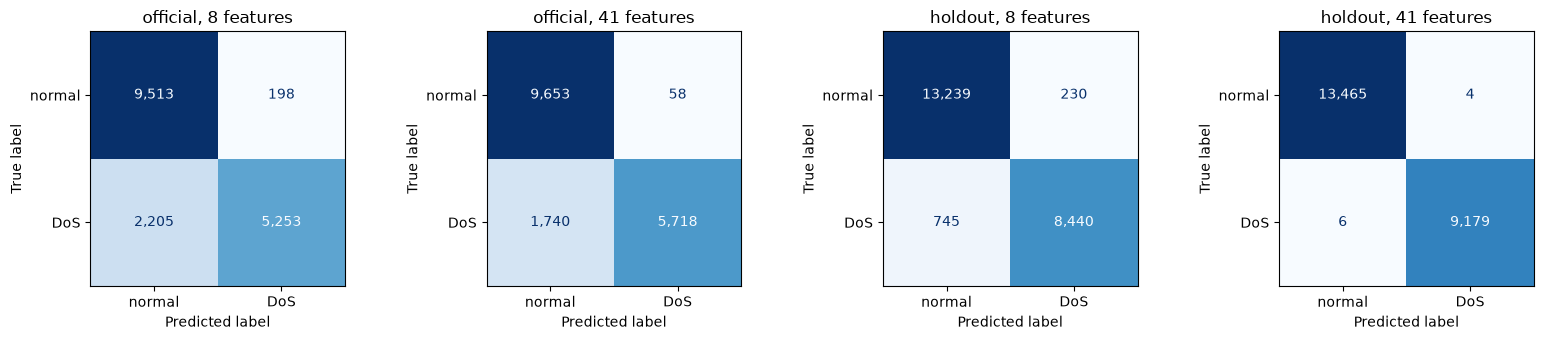

In [5]:
plot_confusions(results);

## Choosing k

Small k follows the training data closely; large k smooths the decision. Official split, 8 features.

In [6]:
ks = [1, 3, 5, 7, 9, 15, 25]
sweep = {f"k={k}": evaluate(MODELS["knn"](k=k), official) for k in ks}
k_table = metrics_table(sweep)[["accuracy", "precision", "recall", "f1", "recall_unseen"]]
k_table

,accuracy,precision,recall,f1,recall_unseen
k=1,0.8490,0.9259,0.7092,0.8032,0.3285
k=3,0.8565,0.9491,0.7076,0.8107,0.3279
k=5,0.8600,0.9637,0.7043,0.8139,0.3215
k=7,0.8651,0.9789,0.7046,0.8194,0.3203
k=9,0.8653,0.9815,0.7031,0.8193,0.3157
k=15,0.8674,0.9867,0.7043,0.8219,0.3203
k=25,0.8694,0.9888,0.7073,0.8247,0.3238


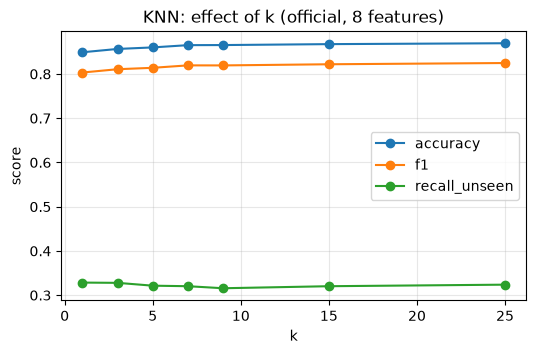

In [7]:
ax = k_table[["accuracy", "f1", "recall_unseen"]].set_axis(ks).plot(marker="o", figsize=(6, 3.5))
ax.set(xlabel="k", ylabel="score", title="KNN: effect of k (official, 8 features)")
ax.grid(alpha=0.3)

## Takeaways

- **Close to the paper's reported numbers only on the easy split.** On the holdout split with 8 features, accuracy is 95.7% (paper: 98.5%). On the official test file it drops to 86.0%, mostly because recall falls to 70%.
- **Unseen attack types are the problem.** KNN catches 82% of DoS attack types it saw in training but only 32% of new ones. With 41 features, seen recall rises to 97.5% while unseen recall falls to 7%: more features let it match known attacks more tightly, and new ones look less like any of them.
- **k barely matters.** Going from k = 1 to k = 25 raises accuracy only from 84.9% to 86.9%, mainly through precision. Recall stays around 70%, so changing k cannot fix the unseen-attack gap.
- **Slowest to predict.** KNN compares every test row to every training row, so it takes about 1–2 s to predict (timing depends on the machine) versus at most about 0.2 s for the other models.